**Name:** Ibrahim Khaled Al-Khamis

**Id:** 2240004075

**Section:** 7MA01

**Course:**   ARTI 403 – Image Processing

---
# Lab 9:   Morphological Operations

### Task 1: Apply morphological operations

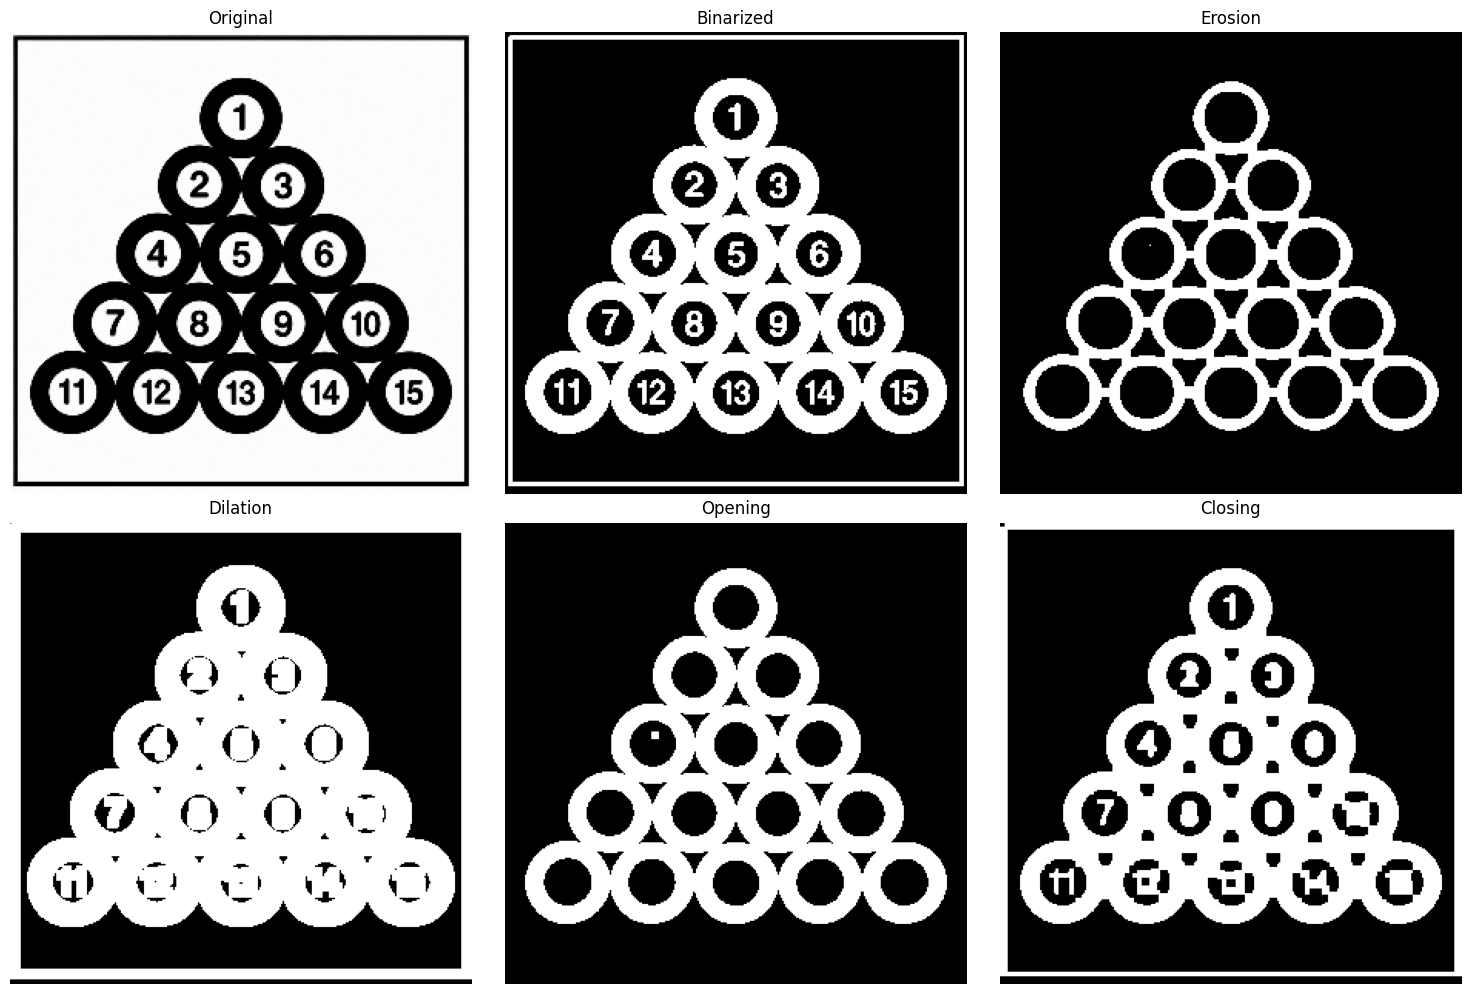

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('Balls.png', 0)
img = cv2.resize(img,(300,300))
# Binarize image (Inverse so objects are white)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)

eroded_img = cv2.erode(binary, kernel, iterations=1)
dilated_img = cv2.dilate(binary, kernel, iterations=1)
opened_img = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed_img = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(2, 3, 2), plt.imshow(binary, cmap='gray'), plt.title('Binarized'), plt.axis('off')
plt.subplot(2, 3, 3), plt.imshow(eroded_img, cmap='gray'), plt.title('Erosion'), plt.axis('off')
plt.subplot(2, 3, 4), plt.imshow(dilated_img, cmap='gray'), plt.title('Dilation'), plt.axis('off')
plt.subplot(2, 3, 5), plt.imshow(opened_img, cmap='gray'), plt.title('Opening'), plt.axis('off')
plt.subplot(2, 3, 6), plt.imshow(closed_img, cmap='gray'), plt.title('Closing'), plt.axis('off')

plt.tight_layout()
plt.show()

### Task 2: Experiment with structuring elements

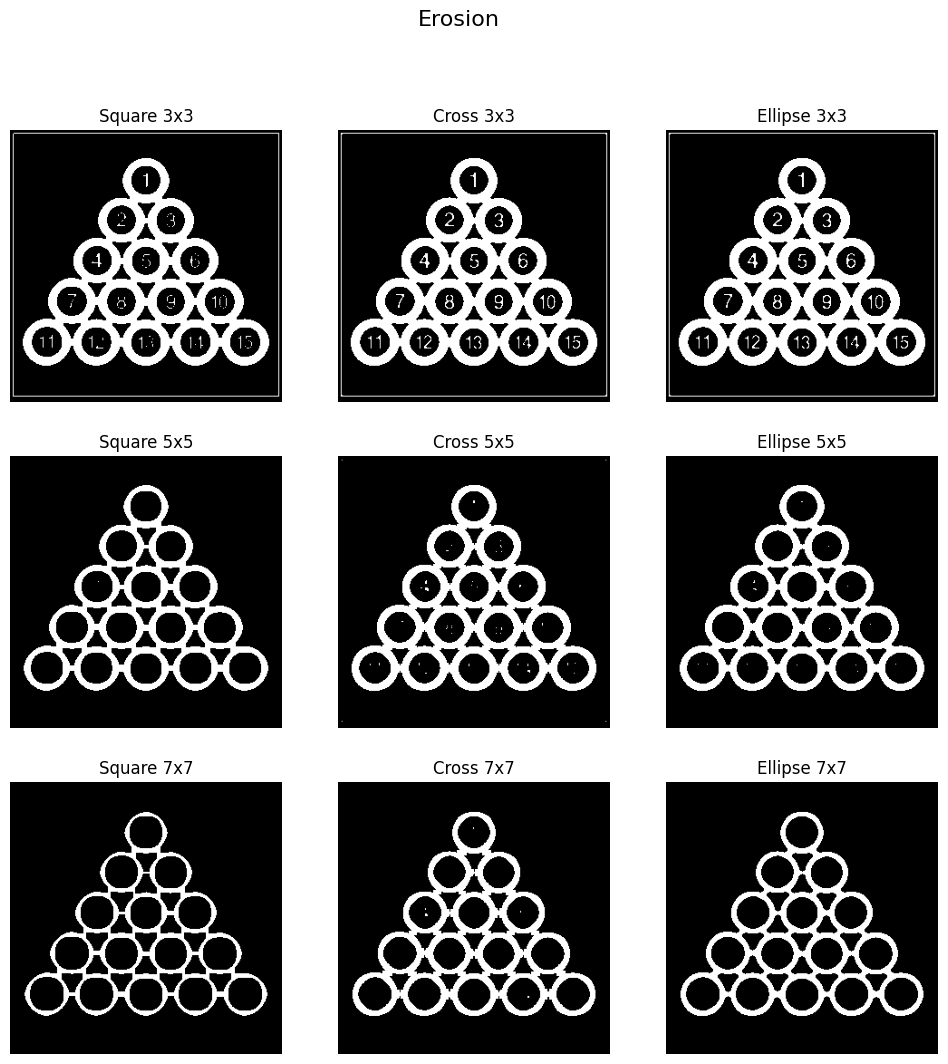

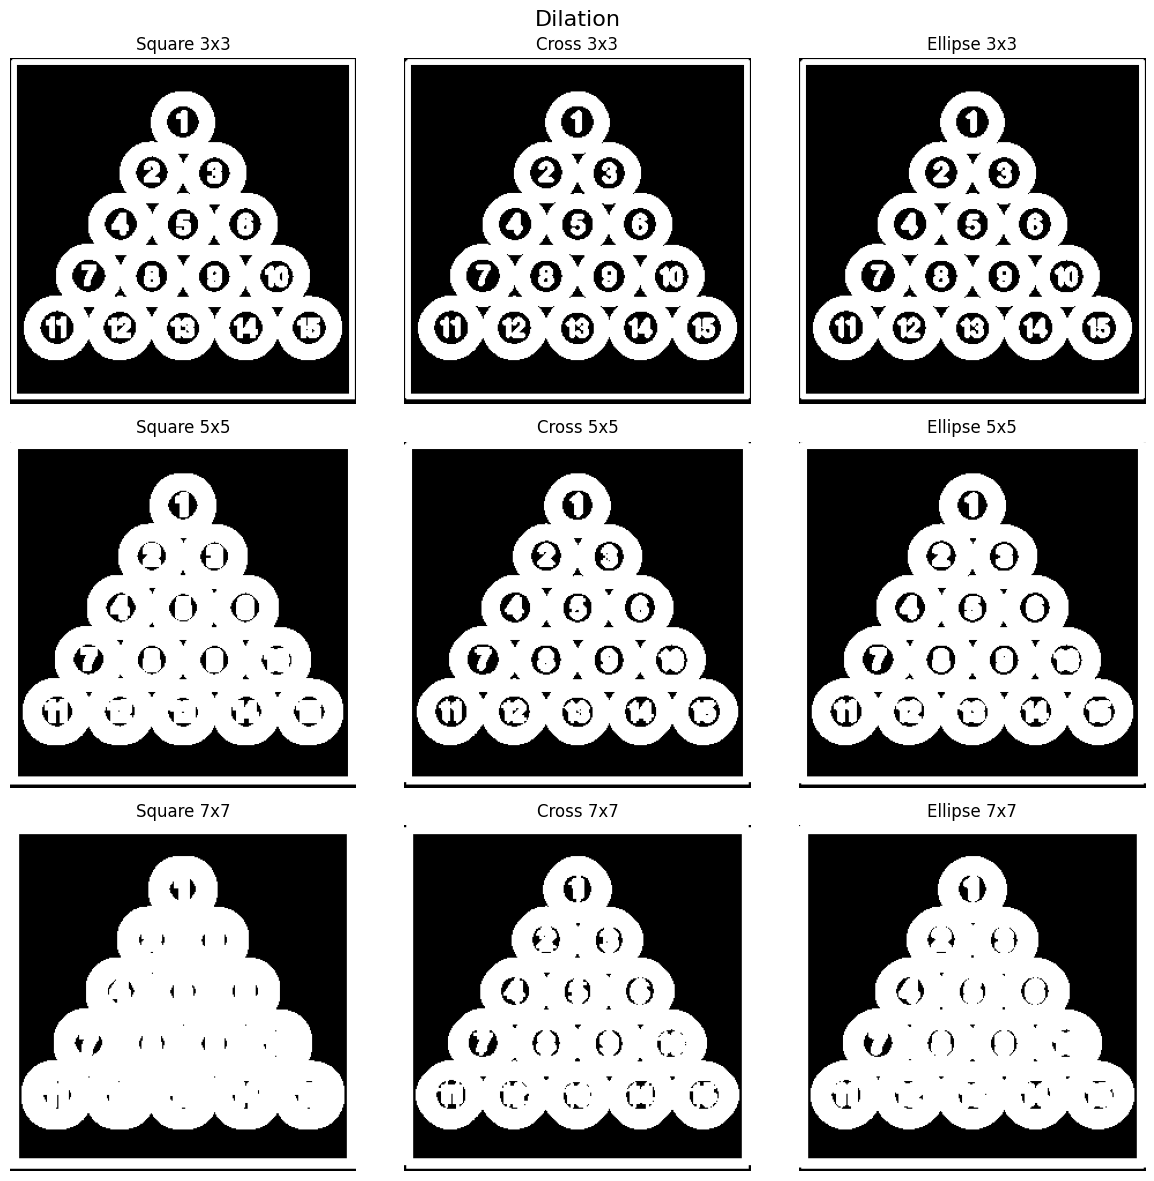

In [5]:
shapes = {
    'Square': cv2.MORPH_RECT,
    'Cross': cv2.MORPH_CROSS,
    'Ellipse': cv2.MORPH_ELLIPSE
}
sizes = [3, 5, 7]

fig_erode, axes_erode = plt.subplots(len(sizes), len(shapes), figsize=(12, 12))
fig_erode.suptitle('Erosion', fontsize=16)

fig_dilate, axes_dilate = plt.subplots(len(sizes), len(shapes), figsize=(12, 12))
fig_dilate.suptitle('Dilation', fontsize=16)

for i, size in enumerate(sizes):
    for j, (shape_name, shape_type) in enumerate(shapes.items()):
        
        kernel = cv2.getStructuringElement(shape_type, (size, size))
        
        eroded = cv2.erode(binary, kernel, iterations=1)
        dilated = cv2.dilate(binary, kernel, iterations=1)
        
        axes_erode[i, j].imshow(eroded, cmap='gray')
        axes_erode[i, j].set_title(f'{shape_name} {size}x{size}')
        axes_erode[i, j].axis('off')
        
        axes_dilate[i, j].imshow(dilated, cmap='gray')
        axes_dilate[i, j].set_title(f'{shape_name} {size}x{size}')
        axes_dilate[i, j].axis('off')

plt.tight_layout()
plt.show()

---